# Fase 4 & 5: Entrenamiento, Optimización y Calibración de Probabilidades

---

## Contenido del Notebook
1. **Modelos Base**: Regresión Logística y Random Forest.
2. **Modelos de Gradiente Avanzados**: LightGBM / XGBoost.
3. **Comparación Global de Curvas ROC y PR**.
4. **Calibración Probabilística de Riesgo (`CalibratedClassifierCV`) & Brier Score**.
5. **Optimización del Umbral de Decisión Clínico (*Medical Threshold Tuning*)**.


In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import TARGET_COL, RANDOM_STATE
from src.data_loader import load_processed_splits
from src.models import (
    build_logistic_baseline_pipeline,
    build_random_forest_pipeline,
    build_lightgbm_pipeline,
    calibrate_model,
)
from src.evaluation import (
    compute_metrics,
    metrics_to_dataframe,
    plot_roc_pr_comparison,
    plot_calibration_curves,
)

train_df, val_df, test_df = load_processed_splits()
X_train, y_train = train_df.drop(columns=[TARGET_COL]), train_df[TARGET_COL]
X_val, y_val = val_df.drop(columns=[TARGET_COL]), val_df[TARGET_COL]
X_test, y_test = test_df.drop(columns=[TARGET_COL]), test_df[TARGET_COL]

print(f"Particiones listas: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")


Particiones listas: Train=70000, Val=15000, Test=15000


## 1. Entrenamiento de Modelos Base
Comenzamos entrenando el modelo base de Regresión Logística (con codificación correcta y escalado estándar) y el ensamble de Random Forest.


In [2]:
%%time
# 1. Regresión Logística Baseline
lr_model = build_logistic_baseline_pipeline(C=1.0)
lr_model.fit(X_train, y_train)

# 2. Random Forest Baseline
rf_model = build_random_forest_pipeline(n_estimators=150, max_depth=12)
rf_model.fit(X_train, y_train)

print("Modelos base entrenados exitosamente!")


Modelos base entrenados exitosamente!
CPU times: user 32.5 s, sys: 169 ms, total: 32.7 s
Wall time: 13.4 s


## 2. Entrenamiento de Modelo de Gradiente (LightGBM)
LightGBM suele obtener el mejor compromiso entre velocidad y discriminación en datos tabulares de 100,000 registros.


In [3]:
%%time
lgb_model = build_lightgbm_pipeline(n_estimators=300, learning_rate=0.05, max_depth=6)
lgb_model.fit(X_train, y_train)
print("LightGBM entrenado exitosamente!")


LightGBM entrenado exitosamente!
CPU times: user 43.8 s, sys: 249 ms, total: 44.1 s
Wall time: 22.5 s


## 3. Comparación de Métricas en el Conjunto de Validación
Evaluamos el desempeño discriminativo sin tocar el conjunto de prueba (Test).


,ROC-AUC,PR-AUC,Brier Score,Sensitivity (Recall),Specificity,Precision,F1-Score,Accuracy,True Positives,False Negatives,False Positives,True Negatives
Logistic Regression,0.8530,0.8334,0.1554,0.7303,0.8100,0.7666,0.7480,0.7733,5048.0,1864.0,1537.0,6551.0
Random Forest,0.8417,0.8209,0.1633,0.7096,0.8092,0.7607,0.7343,0.7633,4905.0,2007.0,1543.0,6545.0
LightGBM,0.8492,0.8293,0.1574,0.7257,0.8058,0.7615,0.7432,0.7689,5016.0,1896.0,1571.0,6517.0


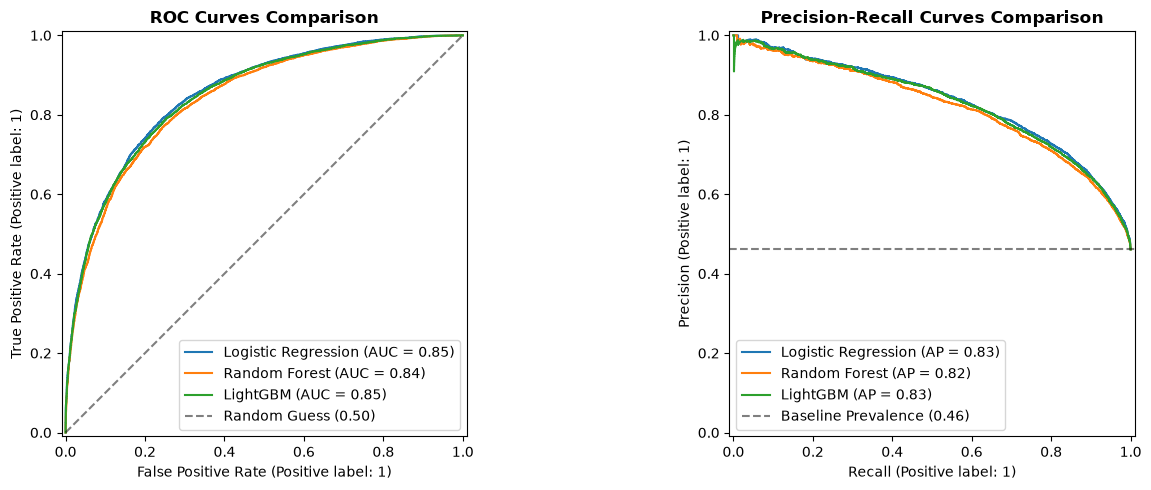

In [4]:
models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "LightGBM": lgb_model,
}

val_metrics = {}
for name, model in models.items():
    preds = model.predict(X_val)
    probas = model.predict_proba(X_val)[:, 1]
    val_metrics[name] = compute_metrics(y_val, preds, probas)

df_results = metrics_to_dataframe(val_metrics)
display(df_results.round(4))

plot_roc_pr_comparison(models, X_val, y_val)


### Calibración de Probabilidades con `CalibratedClassifierCV`
En aplicaciones de salud pública y clínicas, no basta con predecir 0 o 1: se requiere una probabilidad empírica confiable (estimador de riesgo continuo $\hat{P}(Y=1 \mid X)$).

1. Aplica `calibrate_model()` (o directamente `CalibratedClassifierCV`) al mejor modelo (ej. `lgb_model`).
2. Ajusta el calibrador utilizando el conjunto de validación (`cv='prefit'`) o validación cruzada interna.
3. Evalúa la reducción en el **Brier Score** (donde un valor menor indica mejor calibración).
4. Utiliza `plot_calibration_curves()` para comparar la curva de confiabilidad antes y después de calibrar.


Brier Score Sin Calibrar: 0.1574
Brier Score Calibrado (Platt Scaling): 0.1573
Mejora relativa en calibración: 0.02%


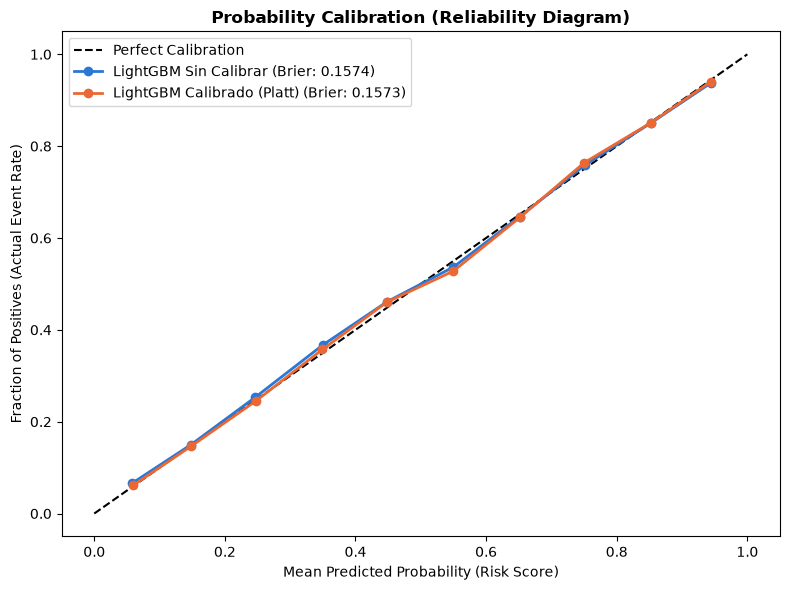

In [5]:
# TODO: Calibra el modelo seleccionado y compara Brier Score y curvas de confiabilidad
cal_lgb = calibrate_model(lgb_model, method='sigmoid', cv='prefit')
cal_lgb.fit(X_val, y_val)

# Probabilidades estimadas en validación
val_proba_uncal = lgb_model.predict_proba(X_val)[:, 1]
val_proba_cal = cal_lgb.predict_proba(X_val)[:, 1]

brier_uncal = compute_metrics(y_val, (val_proba_uncal >= 0.5).astype(int), val_proba_uncal)["Brier Score"]
brier_cal = compute_metrics(y_val, (val_proba_cal >= 0.5).astype(int), val_proba_cal)["Brier Score"]

print(f"Brier Score Sin Calibrar: {brier_uncal:.4f}")
print(f"Brier Score Calibrado (Platt Scaling): {brier_cal:.4f}")
print(f"Mejora relativa en calibración: {((brier_uncal - brier_cal) / brier_uncal) * 100:.2f}%")

plot_calibration_curves(
    {'LightGBM Sin Calibrar': lgb_model, 'LightGBM Calibrado (Platt)': cal_lgb},
    X_val,
    y_val,
    save_name="calibracion_lightgbm.png"
)


### Ajuste de Umbral de Decisión Clínico (*Medical Threshold Tuning*)
Por defecto, Scikit-Learn utiliza un umbral de corte de $\tau = 0.50$.  
En el diagnóstico médico de cardiopatías, **un Falso Negativo (paciente enfermo clasificado como sano) es mucho más grave que un Falso Positivo**.

1. Itera a través de una malla de umbrales $\tau \in [0.10, 0.90]$.
2. Calcula la Sensibilidad (*Recall*) y la Precisión para cada umbral.
3. Encuentra el umbral óptimo que garantiza una **Sensibilidad $\ge 85\%$ o $90\%$**, minimizando falsos negativos.
4. Grafica la curva de Recall vs Precision en función del umbral.


Umbral clínico óptimo (Recall >= 90%): tau = 0.25
Sensibilidad alcanzada: 0.9062
Precisión correspondiente: 0.6363
F1-Score correspondiente: 0.7477


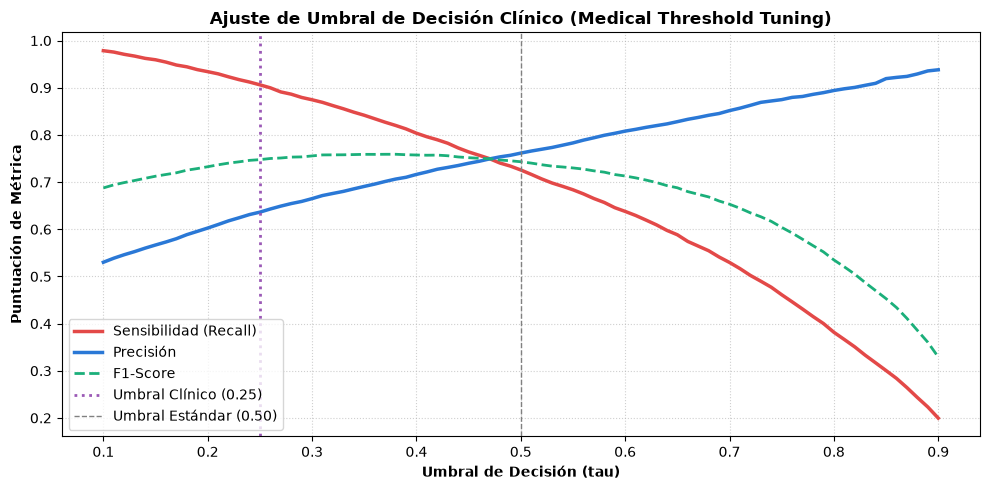

In [6]:
# TODO: Implementa la búsqueda del umbral óptimo
from sklearn.metrics import recall_score, precision_score, f1_score

thresholds = np.linspace(0.1, 0.9, 81)
y_proba_val = lgb_model.predict_proba(X_val)[:, 1]

recalls = []
precisions = []
f1_scores = []

for t in thresholds:
    y_pred_t = (y_proba_val >= t).astype(int)
    recalls.append(recall_score(y_val, y_pred_t, zero_division=0))
    precisions.append(precision_score(y_val, y_pred_t, zero_division=0))
    f1_scores.append(f1_score(y_val, y_pred_t, zero_division=0))

valid_idx = [i for i, r in enumerate(recalls) if r >= 0.90]
optimal_idx = valid_idx[-1] if valid_idx else 0
optimal_thresh = thresholds[optimal_idx]

print(f"Umbral clínico óptimo (Recall >= 90%): tau = {optimal_thresh:.2f}")
print(f"Sensibilidad alcanzada: {recalls[optimal_idx]:.4f}")
print(f"Precisión correspondiente: {precisions[optimal_idx]:.4f}")
print(f"F1-Score correspondiente: {f1_scores[optimal_idx]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(thresholds, recalls, label='Sensibilidad (Recall)', color='#e34948', linewidth=2.5)
plt.plot(thresholds, precisions, label='Precisión', color='#2a78d6', linewidth=2.5)
plt.plot(thresholds, f1_scores, label='F1-Score', color='#1baf7a', linestyle='--', linewidth=2)
plt.axvline(optimal_thresh, color='#9b59b6', linestyle=':', linewidth=2, label=f'Umbral Clínico ({optimal_thresh:.2f})')
plt.axvline(0.50, color='gray', linestyle='--', linewidth=1, label='Umbral Estándar (0.50)')
plt.title('Ajuste de Umbral de Decisión Clínico (Medical Threshold Tuning)', fontweight='bold')
plt.xlabel('Umbral de Decisión (tau)', fontweight='bold')
plt.ylabel('Puntuación de Métrica', fontweight='bold')
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
